# Preprocesamiento de datos
Para poder hacer un análisis correcto de los datos de Ice, primero obtendré la información base del dataframe y observaré qué valores contiene cada columna. Tendré que tratar con los datos nulos que existan  y convertir el tipo de datos para las columnas necesarias.

In [1]:
#Importo las librerías necesarias
import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats as st
import numpy as np

In [2]:
#Abro el archivo de datos y veo la información base, al igual que las primeras filas.
games= pd.read_csv('/datasets/games.csv')
print(games.info())
print(games.head())

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 16715 entries, 0 to 16714
,Data columns (total 11 columns):
, #   Column           Non-Null Count  Dtype  
,---  ------           --------------  -----  
, 0   Name             16713 non-null  object 
, 1   Platform         16715 non-null  object 
, 2   Year_of_Release  16446 non-null  float64
, 3   Genre            16713 non-null  object 
, 4   NA_sales         16715 non-null  float64
, 5   EU_sales         16715 non-null  float64
, 6   JP_sales         16715 non-null  float64
, 7   Other_sales      16715 non-null  float64
, 8   Critic_Score     8137 non-null   float64
, 9   User_Score       10014 non-null  object 
, 10  Rating           9949 non-null   object 
,dtypes: float64(6), object(5)
,memory usage: 1.4+ MB
,None
,                       Name Platform  Year_of_Release         Genre  NA_sales  \
,0                Wii Sports      Wii           2006.0        Sports     41.36   
,1         Super Mario Bros.      NES           1985.0

In [3]:
#Creo un bucle para convertir los nombres de columnas a minúsculas
columns_new=[]
for old in games.columns:
    lowered= old.lower()
    columns_new.append(lowered)
#Reemplazo los nombres de columnas y compruebo    
games.columns= columns_new
print(games.columns)

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
,       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
,      dtype='object')


In [4]:
# Verificar en el dataset la palabra TBD
tbd_count = games['platform'].str.contains('TBD', na=False).sum()
print(tbd_count)

0


In [5]:
#Compruebo cuántos valores nulos hay en year of release
años_nulos= games['year_of_release'].isna().sum()
print(f'Hay tantos valores nulos en la columna year_of_release: {años_nulos}')

Hay tantos valores nulos en la columna year_of_release: 269


In [6]:
#Relleno los valores nan de la columna de año con 0 y transformo los datos a enteros.
games['year_of_release'].fillna(0,inplace=True)
games['year_of_release']=games['year_of_release'].astype('int')
#Compruebo el cambio
print(games['year_of_release'].dtypes)

int64


In [7]:
#Compruebo los valores nulos en la columna name
nombres_nulos= games['name'].isna().sum()
print(f'Hay tantos valores nulos en la name: {nombres_nulos}')

Hay tantos valores nulos en la name: 2


In [8]:
#Reviso qué filas tienen esos valores nulos
nombre_nulo_test=games[games['name'].isna()]
print(nombre_nulo_test.head())
#Relleno los valores nulos con unknown
games['name'].fillna('unknown',inplace=True)
print(games[games['name']=='unknown'])

      name platform  year_of_release genre  na_sales  eu_sales  jp_sales  \
,659    NaN      GEN             1993   NaN      1.78      0.53      0.00   
,14244  NaN      GEN             1993   NaN      0.00      0.00      0.03   
,
,       other_sales  critic_score user_score rating  
,659           0.08           NaN        NaN    NaN  
,14244         0.00           NaN        NaN    NaN  
,          name platform  year_of_release genre  na_sales  eu_sales  jp_sales  \
,659    unknown      GEN             1993   NaN      1.78      0.53      0.00   
,14244  unknown      GEN             1993   NaN      0.00      0.00      0.03   
,
,       other_sales  critic_score user_score rating  
,659           0.08           NaN        NaN    NaN  
,14244         0.00           NaN        NaN    NaN  


In [9]:
#Relleno los valores nulos de genre con la palabra unknown
games['genre'].fillna('unknown',inplace=True)
print(games[games['genre']=='unknown'])


          name platform  year_of_release    genre  na_sales  eu_sales  \
,659    unknown      GEN             1993  unknown      1.78      0.53   
,14244  unknown      GEN             1993  unknown      0.00      0.00   
,
,       jp_sales  other_sales  critic_score user_score rating  
,659        0.00         0.08           NaN        NaN    NaN  
,14244      0.03         0.00           NaN        NaN    NaN  


In [10]:
#Reviso los valores nulos de critic score
critic_null_test= games['critic_score'].isna().sum()
#Saco la mediana y la media para comprobar si no son valores atípicos significativos
critic_median=games['critic_score'].median()
critic_mean=games['critic_score'].mean()
print(critic_null_test)
print(critic_median)
print(critic_mean)

8578
,71.0
,68.96767850559173


In [11]:
#Relleno los valores nulos de critic score con la media
games['critic_score'].fillna(critic_mean,inplace=True)

In [12]:
#Transformo user score a float
games['user_score']=pd.to_numeric(games['user_score'],errors='coerce')
#Saco la mediana y la media para comprobar si no son valores atípicos significativos
userscore_median=games['user_score'].median()
userscore_mean=games['user_score'].mean()

print(userscore_median)
print(userscore_mean)

7.5
,7.125046113306982


In [13]:
#Relleno los valores nulos de user score con la media
games['user_score'].fillna(userscore_mean,inplace=True)

In [14]:
#Reviso los valores nulos de rating
rating_null_test= games['rating'].isna().sum()
print(rating_null_test)

6766


In [15]:
#Relleno los valores nulos de rating con la palabra unknown
games['rating'].fillna('unknown',inplace=True)

In [16]:
#Vuelvo a comprobar la info de todo el dataframe
print(games.info())

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 16715 entries, 0 to 16714
,Data columns (total 11 columns):
, #   Column           Non-Null Count  Dtype  
,---  ------           --------------  -----  
, 0   name             16715 non-null  object 
, 1   platform         16715 non-null  object 
, 2   year_of_release  16715 non-null  int64  
, 3   genre            16715 non-null  object 
, 4   na_sales         16715 non-null  float64
, 5   eu_sales         16715 non-null  float64
, 6   jp_sales         16715 non-null  float64
, 7   other_sales      16715 non-null  float64
, 8   critic_score     16715 non-null  float64
, 9   user_score       16715 non-null  float64
, 10  rating           16715 non-null  object 
,dtypes: float64(6), int64(1), object(4)
,memory usage: 1.4+ MB
,None


In [17]:
#Comruebo si hay filas duplicadas en todo el dataset
games_duplicated_test= games.duplicated().sum()
print(games_duplicated_test)

0


## Conclusiones del preprocesamiento de datos:
- En la columna name sólo habían dos valores nulos, que los reemplacé con la palabra unknown.
- En year_of_release había 269 valores nulos, por lo que los reemplacé con 0 para luego poder encontrarlos fácilmente y borrarlos. Pero antes de eso, como los datos estaban guardados como flotantes, los convertí a enteros .
- En genre sólo había 2 valores nulos y los reemplacé con la palabra unknown.
- En critic score había 8578 valores nulos, así que obtuve la media, la mediana y comprobé que no había mucha diferencia entre ambos valores, por lo que procedí a reemplazar los nulos con la media.
- Los datos de user score estaban guardados como object, así que primero los convertí a flotantes, ignorando los nulos. Luego hice lo mismo que en critic score, comprobé que la media y la mediana no diferían demasiado y procedí a reemplazar los nulos con la media.
- Para los valores nulos de rating únicamente los reemplacé con la palabra unknown.
- Finalmente sólo comprobé si se hicieron todos los cambios y que no había filas totalmente duplicadas.

# Ventas totales
A continuación creo una nueva columna que representa la suma de las ventas de las 3 regiones  con las que se trabaja. Para hacer eso primero elimino todas las filas cuyo año sea 0 (como reemplazamos anteriormente), ya que esos datos sólo confundirían los resultados del análisis al no poder deducir de qué año proceden esas ganancias.

In [18]:
#Elimino las filas en las que el año sea 0 (los valores nan que se reemplazaron)
games= games[games['year_of_release']!=0]
print(games.info())
#Calculo las ventas totales con un bucle
total_sales=[]
for index,fila in games.iterrows():
    sum_sales= fila['na_sales']+fila['eu_sales']+fila['jp_sales']+fila['other_sales']
    total_sales.append(sum_sales)
#Agrego la nueva columna con las ventas totales
games['total_sales']=total_sales
print(games.sample(5))

<class 'pandas.core.frame.DataFrame'>
,Int64Index: 16446 entries, 0 to 16714
,Data columns (total 11 columns):
, #   Column           Non-Null Count  Dtype  
,---  ------           --------------  -----  
, 0   name             16446 non-null  object 
, 1   platform         16446 non-null  object 
, 2   year_of_release  16446 non-null  int64  
, 3   genre            16446 non-null  object 
, 4   na_sales         16446 non-null  float64
, 5   eu_sales         16446 non-null  float64
, 6   jp_sales         16446 non-null  float64
, 7   other_sales      16446 non-null  float64
, 8   critic_score     16446 non-null  float64
, 9   user_score       16446 non-null  float64
, 10  rating           16446 non-null  object 
,dtypes: float64(6), int64(1), object(4)
,memory usage: 1.5+ MB
,None
,                                 name platform  year_of_release     genre  \
,350                   Resident Evil 4      PS2             2005    Action   
,7993                     The Smurfs 2       DS     

# Análisis de datos
En esta fase del proyecto ya puedo tratar con los datos limpios de todas las columnas y obtener información sobre el número de juegos lanzados por año, cómo varían las ventas de una plataforma a otra para saber cuáles son más populares, definir desde qué año la información es más relevante para identificar patrones, ver cómo afectan las reseñas de usuarios y críticos a las ventas, y finalmente observar la distribución de ventas por género.

In [19]:
#Comprobación rápida de si hay nombres duplicados de los juegos
duplicated_names=games['name'].duplicated().sum()
print(duplicated_names)
#Cuento cuántos juegos únicos fueron lanzados en diferentes años
games_per_year= games.groupby('year_of_release')['name'].nunique()
print(games_per_year)

5019
,year_of_release
,1980       9
,1981      46
,1982      36
,1983      17
,1984      14
,1985      14
,1986      21
,1987      16
,1988      15
,1989      17
,1990      16
,1991      40
,1992      41
,1993      60
,1994     117
,1995     215
,1996     258
,1997     282
,1998     364
,1999     326
,2000     325
,2001     428
,2002     631
,2003     546
,2004     550
,2005     657
,2006     773
,2007     884
,2008    1039
,2009    1001
,2010     900
,2011     779
,2012     446
,2013     335
,2014     319
,2015     362
,2016     297
,Name: name, dtype: int64


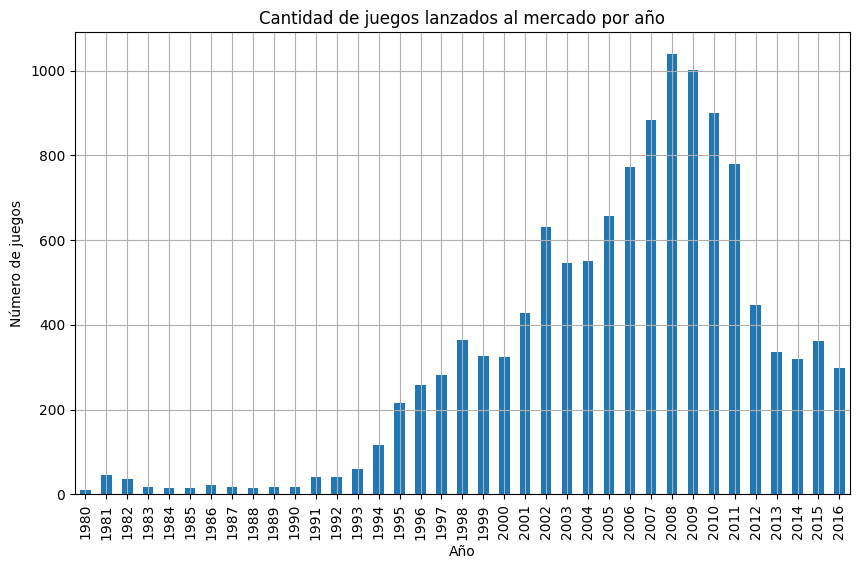

In [20]:
#Grafico la anterior información con barras
games_per_year.plot(kind='bar',
                    title='Cantidad de juegos lanzados al mercado por año',
                   xlabel='Año',
                   ylabel='Número de juegos',
                   grid=True,
                   figsize=[10,6])
plt.show()

In [21]:
#Agrupo las  ventas totales por plataforma 
sales_per_platform= games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
top_platforms= sales_per_platform.head(10)
print(top_platforms)
#Filtro las 10 plataformas más rentables para poder graficar su ciclo de vida
top_platforms_years= games[games['platform'].isin(top_platforms.index)].groupby(['platform','year_of_release'])['total_sales'].sum().unstack(level=0)


platform
,PS2     1233.56
,X360     961.24
,PS3      931.34
,Wii      891.18
,DS       802.78
,PS       727.58
,PS4      314.14
,GBA      312.88
,PSP      289.53
,3DS      257.81
,Name: total_sales, dtype: float64


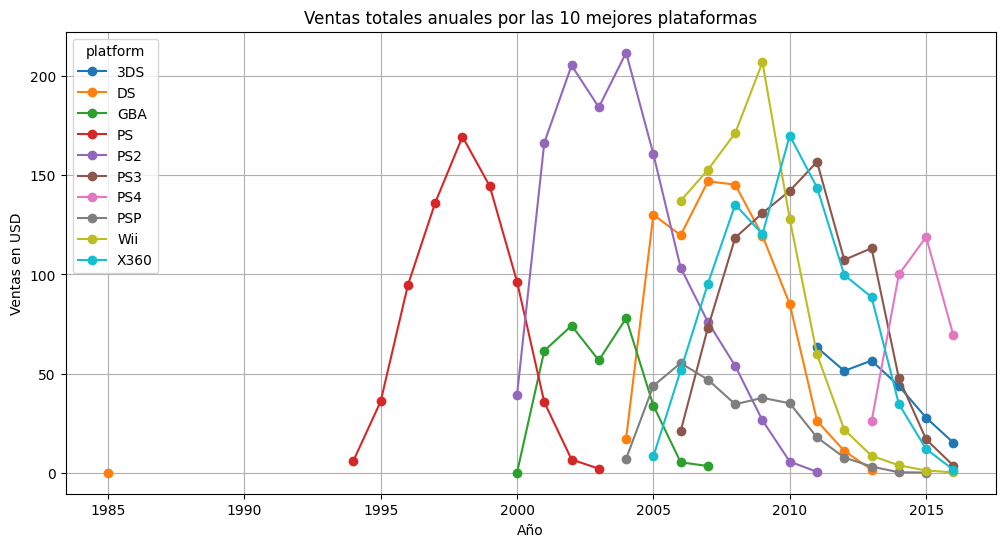

In [22]:
#Grafico las ventas totales por plataforma y por año
top_platforms_years.plot(kind='line',
                         style='o-',
                       title='Ventas totales anuales por las 10 mejores plataformas',
                       xlabel='Año',
                       ylabel='Ventas en USD',
                       grid=True,
                        figsize=[12,6])

plt.show()


platform
,SAT     33.59
,GEN     30.77
,DC      15.95
,SCD      1.86
,NG       1.44
,WS       1.42
,TG16     0.16
,3DO      0.10
,GG       0.04
,PCFX     0.03
,Name: total_sales, dtype: float64


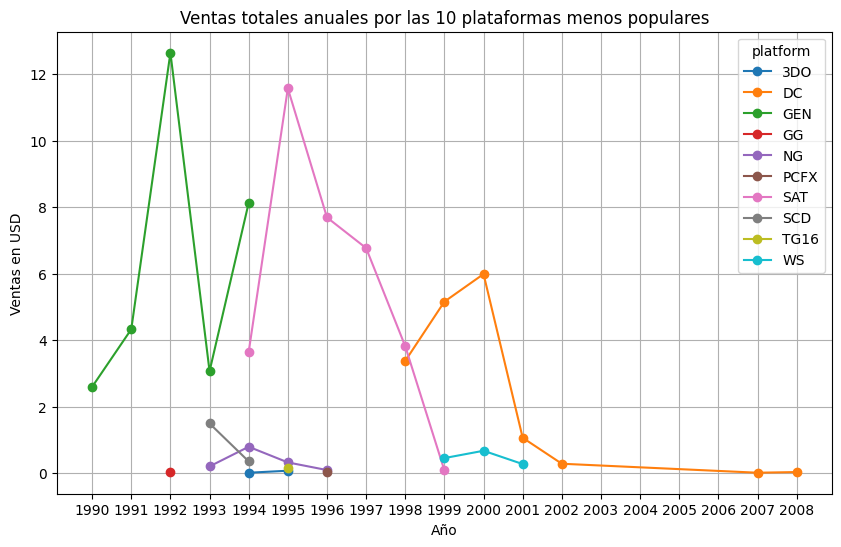

In [23]:
#Filtro las plataformas menos rentables para igualmente graficar su ciclo de vida
worst_platforms= sales_per_platform.tail(10)
print(worst_platforms)
worst_platforms_years= games[games['platform'].isin(worst_platforms.index)].groupby(['platform','year_of_release'])['total_sales'].sum().unstack(level=0)
worst_platforms_years.plot(kind='line',
                           style='o-',
                       title='Ventas totales anuales por las 10 plataformas menos populares',
                       xlabel='Año',
                       ylabel='Ventas en USD',
                       grid=True,
                        figsize=[10,6])
plt.xticks(range(int(worst_platforms_years.index.min()), 
                int(worst_platforms_years.index.max()) + 1))
plt.show()

 ### ¿Cuánto tardan generalmente las nuevas plataformas en aparecer y las antiguas en desaparecer?
 
- Haciendo una comparación entre los gráficos de las plataformas más populares y las menos populares encontramos que las primeras tienen mayor auge luego de los 2000 y se demoran entre 3 y 4 años en alcanzar cifras altas/significativas. Mientras que las menos populares se concentran antes de los 2000 y se demoran entre 2 y 4 años en desaparecer, aunque igual se observa como excepción la plataforma DC que nació en 1998 y se mantuvo hasta el 2008, aunque con cifras muy bajas.

- De aquí también se concluye que sería mejor trabajar con datos a partir del año 2001.

In [24]:
#Aquí creo un nuevo dataframe que sólo contenga los videojuegos lanzados a partir del 2001
new_games= games[games['year_of_release']>2001]
#Ordeno por plataforma y sumo las ventas totales para definir qué plataformas fueron más rentables en este periodo de tiempo
leader_platforms= new_games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print(leader_platforms)

platform
,PS2     1027.96
,X360     961.24
,PS3      931.34
,Wii      891.18
,DS       802.76
,PS4      314.14
,PSP      289.53
,3DS      257.81
,GBA      251.28
,XB       228.32
,PC       195.59
,GC       170.39
,XOne     159.32
,WiiU      82.19
,PSV       53.81
,PS         8.74
,DC         0.35
,N64        0.08
,Name: total_sales, dtype: float64


In [25]:
#Aquí organizo los datos de ventas por plataforma y por año para comprobar cómo fue su crecimiento o descenso
growing_test=new_games.groupby(['platform','year_of_release'])['total_sales'].sum().unstack(level=0)
print(growing_test)

platform           3DS    DC      DS    GBA     GC   N64     PC    PS     PS2  \
,year_of_release                                                                 
,2002               NaN  0.29     NaN  74.16  51.81  0.08   8.57  6.67  205.38   
,2003               NaN   NaN     NaN  56.67  50.61   NaN   8.84  2.07  184.31   
,2004               NaN   NaN   17.27  77.91  28.82   NaN  10.39   NaN  211.81   
,2005               NaN   NaN  130.14  33.86  27.62   NaN   4.37   NaN  160.66   
,2006               NaN   NaN  119.81   5.28  11.26   NaN   2.85   NaN  103.42   
,2007               NaN  0.02  146.94   3.40   0.27   NaN   9.28   NaN   75.99   
,2008               NaN  0.04  145.31    NaN    NaN   NaN  12.42   NaN   53.90   
,2009               NaN   NaN  119.54    NaN    NaN   NaN  16.91   NaN   26.40   
,2010               NaN   NaN   85.02    NaN    NaN   NaN  24.28   NaN    5.64   
,2011             63.20   NaN   26.18    NaN    NaN   NaN  35.03   NaN    0.45   
,2012            

In [26]:
# Para cada plataforma, calculo correlación entre año y ventas
correlations = {}
for platform in growing_test.columns:
    # Obtener datos sin valores NaN
    platform_data = growing_test[platform].dropna()
    if len(platform_data) > 1:  # Necesitas al menos 2 puntos
        years = pd.Series(platform_data.index, index=platform_data.index)
        correlation = platform_data.corr(years)
        correlations[platform] = correlation

# Hago un dataframe de las correlaciones por plataforma para mejor visualización
correlation_df = pd.DataFrame(list(correlations.items()), 
                             columns=['Platform', 'Correlation'])
correlation_df = correlation_df.sort_values('Correlation', ascending=False)
print(correlation_df)

   Platform  Correlation
,9       PS4     0.473145
,5        PC     0.269116
,16     XOne     0.175658
,14     X360    -0.258104
,8       PS3    -0.328195
,11      PSV    -0.343676
,2        DS    -0.507911
,10      PSP    -0.676291
,13     WiiU    -0.698379
,15       XB    -0.850702
,12      Wii    -0.875193
,3       GBA    -0.894266
,0       3DS    -0.947055
,7       PS2    -0.971889
,1        DC    -0.975306
,4        GC    -0.976862
,6        PS    -1.000000


De esta última tabla se obtiene que las principales plataformas que tuvieron un crecimiento en estos años fueron la PS4, PC Y Xbox One, en ese orden. Aunque no fue tan significativo y cabe destacar que para todas las plataformas hay la tendencia de crecer cuando salen al mercado y descender con los años y la aparición de otras plataformas, como una competencia constante en la que cada una intenta sacar una mejor versión.

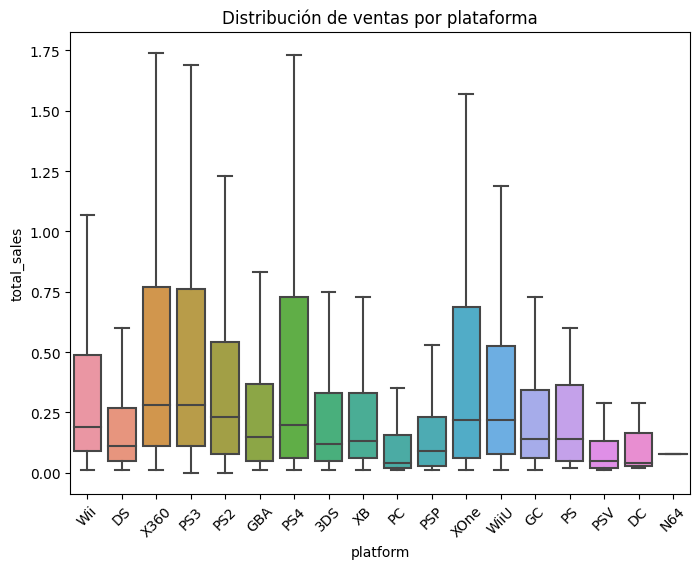

In [32]:
#Aquí procedo a graficar un diagrama de caja que muestra las ventas globales de todos los juegos por plataforma
plt.figure(figsize=(8, 6))
sns.boxplot(data=new_games, x='platform', y='total_sales', showfliers = False)
plt.xticks(rotation=45)
plt.title('Distribución de ventas por plataforma')
plt.show()

Observando este gráfico de caja se obtiene que las ventas promedio de videojuegos de todas las plataformas se mantienen por lo bajo (poco por encima de 0), lo que significa que la mayoría de juegos realmente no despegan tanto en ganancias. Los muchos valores atípicos que se ven por encima del máximo de las primeras plataformas representan aquellos juegos que se volvieron populares y destacaron en el mercado. Por ejemplo en la Wii en la que un juego llegó a generar más de 80 millones de ganancias, mientras que todos los demás se mantuvieron por debajo de los 40 millones.

### Correlación entre reseñas de usuarios/profesionales y las ventas de una plataforma

In [33]:
#Filtro del dataframe de new_games para obtener solo las filas de la plataforma PS4
ps4_sales= new_games[new_games['platform']=='PS4']
print(ps4_sales.head(5))

                              name platform  year_of_release    genre  \
,31       Call of Duty: Black Ops 3      PS4             2015  Shooter   
,42              Grand Theft Auto V      PS4             2014   Action   
,77                         FIFA 16      PS4             2015   Sports   
,87    Star Wars Battlefront (2015)      PS4             2015  Shooter   
,92  Call of Duty: Advanced Warfare      PS4             2014  Shooter   
,
,    na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score  \
,31      6.03      5.86      0.36         2.38     68.967679    7.125046   
,42      3.96      6.31      0.38         1.97     97.000000    8.300000   
,77      1.12      6.12      0.06         1.28     82.000000    4.300000   
,87      2.99      3.49      0.22         1.28     68.967679    7.125046   
,92      2.81      3.48      0.14         1.23     83.000000    5.700000   
,
,     rating  total_sales  
,31  unknown        14.63  
,42        M        12.62  
,77        E 

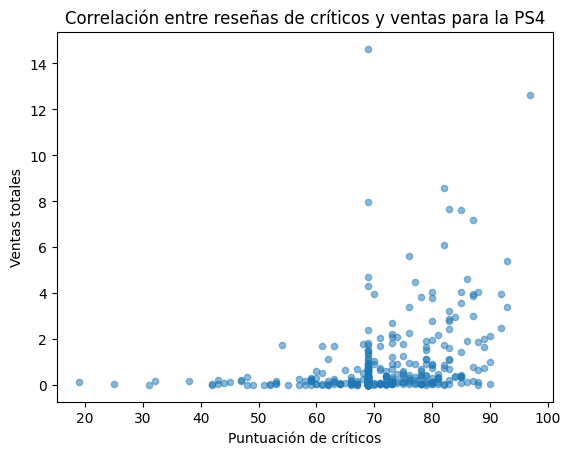

In [34]:
#Hago un gráfico de dispersión entre critic_score y total_sales
ps4_sales.plot(kind='scatter',
              x='critic_score',
              y='total_sales',
              xlabel='Puntuación de críticos',
              ylabel='Ventas totales',
              title='Correlación entre reseñas de críticos y ventas para la PS4',
                alpha=0.5
              )
plt.show()

In [35]:
#Obtengo la correlación entre la reseña de críticos y ventas totales
correlation_critic= ps4_sales['critic_score'].corr(ps4_sales['total_sales'])
print(correlation_critic)


0.3490095802924567


Con el gráfico superior de la correlación entre reseñas de críticos y ventas para la PS4, y el valor obtenido de lo mismo, se observa que si bien hay una tendencia positiva, no es tan significativa. El que los críticos den buenas reseñas de los juegos puede funcionar como un empuje extra para las ventas de los videojuegos, pero no representa una influencia tan grande.

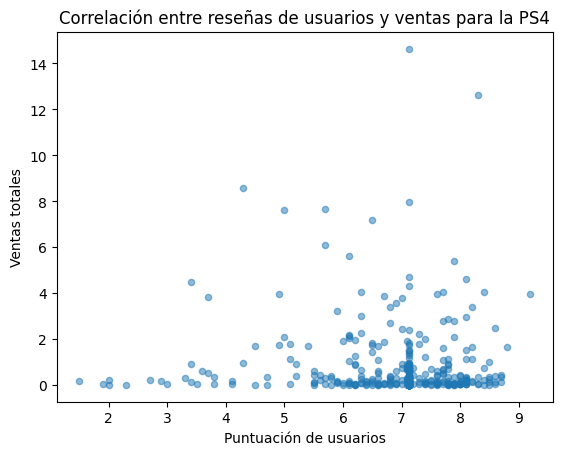

In [36]:
#Hago un gráfico de dispersión entre user_score y total_sales
ps4_sales.plot(kind='scatter',
              x='user_score',
              y='total_sales',
              xlabel='Puntuación de usuarios',
              ylabel='Ventas totales',
              title='Correlación entre reseñas de usuarios y ventas para la PS4',
                alpha=0.5
              )
plt.show()

In [37]:
#Obtengo la correlación entre la reseña de usuarios y ventas totales
correlation_user= ps4_sales['user_score'].corr(ps4_sales['total_sales'])
print(correlation_user)

-0.045390861003324096


Con el gráfico superior de la correlación entre reseñas de usuarios y ventas para la PS4, y el valor obtenido de lo mismo, se observa la tendecia es ligeramente negativa, pero muy cercana a cero. Las calificaciones que dan los usuarios a los juegos no afectan directamente a las ventas que estos generan.

### Comparación de juegos de la PS4 con otras plataformas

In [38]:
#Obtengo la lista de todos los nombres de videojuegos de la PS4
names_ps4= ps4_sales['name']
print(names_ps4.size)

392


In [39]:
#Hago un nuevo data frame que contenga únicamente los juegos que tiene la PS4 para comparar su desempeño en otras plataformas
filtered_games= new_games.query("name in @names_ps4")
print(filtered_games.size)
print(filtered_games.sample(5))

14100
,                               name platform  year_of_release         genre  \
,16142              MLB 15: The Show      PSV             2015        Sports   
,378                   Battlefield 4      PS3             2013       Shooter   
,3045                     Diablo III     XOne             2014  Role-Playing   
,12890                   Chaos;Child      PSV             2015     Adventure   
,8446   One Piece: Pirate Warriors 3      PSV             2015        Action   
,
,       na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score  \
,16142      0.01      0.00      0.00         0.00     68.967679    8.800000   
,378        1.30      1.42      0.27         0.50     80.000000    5.800000   
,3045       0.36      0.24      0.00         0.06     68.967679    7.125046   
,12890      0.00      0.00      0.05         0.00     68.967679    7.125046   
,8446       0.00      0.03      0.13         0.01     76.000000    6.300000   
,
,        rating  total_sales  
,1614

In [40]:
#Creo una tabla dinámica para observar más fácilmente las ventas de cada videojuego por plataforma
sales_comparison= filtered_games.pivot_table(index='name',
                                             columns='platform',
                                             values='total_sales')
print(sales_comparison)

platform                                     3DS  DS  GC  PC  PS2   PS3   PS4  \
,name                                                                            
,7 Days to Die                                NaN NaN NaN NaN  NaN   NaN  0.14   
,Adventure Time: Finn & Jake Investigations  0.09 NaN NaN NaN  NaN  0.08  0.10   
,Aegis of Earth: Protonovus Assault           NaN NaN NaN NaN  NaN  0.02  0.02   
,Agatha Christie's The ABC Murders            NaN NaN NaN NaN  NaN   NaN  0.02   
,Akiba's Trip: Undead & Undressed             NaN NaN NaN NaN  NaN  0.11  0.11   
,...                                          ...  ..  ..  ..  ...   ...   ...   
,Yakuza: Ishin                                NaN NaN NaN NaN  NaN  0.26  0.15   
,Yoru no Nai Kuni                             NaN NaN NaN NaN  NaN  0.05  0.08   
,ZombiU                                       NaN NaN NaN NaN  NaN   NaN  0.06   
,Zombie Army Trilogy                          NaN NaN NaN NaN  NaN   NaN  0.20   
,inFAMOUS: Second

In [41]:
#Obtengo datos estadísticos de cada plataforma para saber con qué plataforma se puede hacer una comparación más certera
#Esta comparación se daría con las plataformas que tengan mayor número de juegos similares a la PS4
print(sales_comparison.describe())

platform        3DS        DS   GC          PC   PS2         PS3         PS4  \
,count     19.000000  2.000000  1.0  117.000000  1.00  178.000000  392.000000   
,mean       0.289474  0.220000  1.3    0.294274  0.06    0.850393    0.801378   
,std        0.233606  0.226274  NaN    0.640130   NaN    2.019661    1.609456   
,min        0.030000  0.060000  1.3    0.010000  0.06    0.010000    0.010000   
,25%        0.125000  0.140000  1.3    0.040000  0.06    0.070000    0.060000   
,50%        0.230000  0.220000  1.3    0.120000  0.06    0.260000    0.200000   
,75%        0.390000  0.300000  1.3    0.250000  0.06    0.752500    0.730000   
,max        0.890000  0.380000  1.3    5.140000  0.06   21.050000   14.630000   
,
,platform       PSP        PSV        Wii       WiiU        X360        XOne  
,count     5.000000  82.000000  11.000000  37.000000  113.000000  217.000000  
,mean      0.236000   0.144512   1.020000   0.342703    1.129646    0.596129  
,std       0.327384   0.233001   

In [42]:
#Filtro los datos para comparar las ventas de juegos entre la PS4 y la Xbox One, borrando los NAN
ps4_vs_xone=sales_comparison[['PS4','XOne']].dropna()
print(ps4_vs_xone.head(10))

platform                                     PS4  XOne
,name                                                  
,7 Days to Die                               0.14  0.05
,Adventure Time: Finn & Jake Investigations  0.10  0.05
,Agatha Christie's The ABC Murders           0.02  0.01
,Alien: Isolation                            1.12  0.50
,Angry Birds Star Wars                       0.22  0.17
,Arslan: The Warriors of Legend              0.09  0.01
,Assassin's Creed Chronicles                 0.08  0.01
,Assassin's Creed IV: Black Flag             2.86  2.24
,Assassin's Creed Syndicate                  3.39  1.29
,Assassin's Creed The Ezio Collection        0.20  0.08


In [43]:
#Filtro los datos para comparar las ventas de juegos entre la PS4 y la PS3, borrando los NAN
ps4_vs_ps3=sales_comparison[['PS4','PS3']].dropna()
print(ps4_vs_ps3.head(10))

platform                                             PS4   PS3
,name                                                          
,Adventure Time: Finn & Jake Investigations          0.10  0.08
,Aegis of Earth: Protonovus Assault                  0.02  0.02
,Akiba's Trip: Undead & Undressed                    0.11  0.11
,Alien: Isolation                                    1.12  0.33
,Angry Birds Star Wars                               0.22  0.29
,Arslan: The Warriors of Legend                      0.09  0.05
,Assassin's Creed IV: Black Flag                     2.86  3.71
,Atelier Sophie: The Alchemist of the Mysterious...  0.12  0.03
,Attack on Titan (KOEI)                              0.29  0.06
,Back to the Future: The Game                        0.18  0.09


Comparando ambas tablas de comparación con los 10 juegos principales vendidos, se observa que la PS4 tiene mayor rentabilidad para los mismos juegos que la Xbox One, por ejemplo en el juego de Assassin's Creed Syndicate, para el que la PS4 generó 3.39 millones y la Xbox One solo 1.29 millones. De igual manera los mismos juegos también se desempeñan mejor en la PS4 que en la PS3, aunque no hay diferencias tan grandes por lo que son de la misma empresa, y en juegos particulares la PS3 sí tiene mejores ventas que la 4.

In [44]:
#Filtro los juegos por su género, para ver cuánto genera cada uno
genre_filter= new_games.groupby('genre')['total_sales'].sum().sort_values(ascending=False)
print(genre_filter)

genre
,Action          1432.80
,Sports          1038.22
,Shooter          881.06
,Misc             686.41
,Role-Playing     680.15
,Racing           485.23
,Platform         439.04
,Simulation       312.50
,Fighting         273.54
,Adventure        171.64
,Puzzle           126.43
,Strategy          99.01
,Name: total_sales, dtype: float64


Al sumar las ventas totales de cada género, se saca que los más rentables son los juegos de Action, Sports y Shooter. No se podría generalizar sobre estos resultados al tratar con distintas regiones, puede que otros géneros sean más rentables en europa que en américa, pero si nos permite formar una noción de los gustos de los gamers.

# PERFILES DE USUARIO POR REGIÓN
En esta fase me encargo de filtrar las ventas totales por región y por plataforma, para poder hacer una comparación y observar cuáles tienen mejor desempeño.

In [45]:
#Filtro las plataformas más rentables para norteamerica
na_platform= new_games.groupby('platform')['na_sales'].sum().sort_values(ascending=False)
print(na_platform.head(5))

#Filtro las plataformas más rentables para europa
eu_platform= new_games.groupby('platform')['eu_sales'].sum().sort_values(ascending=False)
print(eu_platform.head(5))

#Filtro las plataformas más rentables para japón
jp_platform= new_games.groupby('platform')['jp_sales'].sum().sort_values(ascending=False)
print(jp_platform.head(5))

platform
,X360    595.74
,Wii     486.87
,PS2     477.35
,PS3     390.13
,DS      380.31
,Name: na_sales, dtype: float64
,platform
,PS3     327.21
,PS2     269.62
,X360    268.32
,Wii     258.32
,DS      188.41
,Name: eu_sales, dtype: float64
,platform
,DS     175.00
,PS2    110.88
,3DS    100.62
,PS3     79.41
,PSP     75.88
,Name: jp_sales, dtype: float64


Comparando las 3 tablas anteriores, se obtuvo las 5 plataformas más rentables para norteamerica, europa y japón. En la primera se observa que la Xbox 360 y la Wii, son las más populares. Para europa, la lista encabeza la PS3 y la PS2. Y para japón, la DS se alza significativamente sobre las demás, siguiéndole la PS2.

In [46]:
#Filtro los generos más rentables para norteamerica
na_genre= new_games.groupby('genre')['na_sales'].sum().sort_values(ascending=False)
print(na_genre.head(5))

#Filtro los generos más rentables para europa
eu_genre= new_games.groupby('genre')['eu_sales'].sum().sort_values(ascending=False)
print(eu_genre.head(5))

#Filtro los generos más rentables para japón
jp_genre= new_games.groupby('genre')['jp_sales'].sum().sort_values(ascending=False)
print(jp_genre.head(5))


genre
,Action          704.67
,Sports          537.84
,Shooter         476.12
,Misc            348.17
,Role-Playing    267.64
,Name: na_sales, dtype: float64
,genre
,Action     436.49
,Sports     315.67
,Shooter    284.35
,Misc       187.55
,Racing     167.63
,Name: eu_sales, dtype: float64
,genre
,Role-Playing    216.36
,Action          122.50
,Misc             81.40
,Sports           65.62
,Platform         49.17
,Name: jp_sales, dtype: float64


Comparando las 3 listas anteriores, se observa que tanto en norteamerica como en europa los géneros más rentables son acción y deportes; mientras que en japón el juego de roles se logra alzar sobre la acción con casi el doble de ganancias, y los deportes bajan a 4to lugar.

In [47]:
#Observo cuáles son las clasificaciones de la columna rating
esrb_info= new_games['rating'].unique()
print(esrb_info)

#Filtro por clasificación ESRB en norteamerica
na_esrb= new_games.groupby('rating')['na_sales'].sum().sort_values(ascending=False)
print(na_esrb)

#Filtro por clasificación ESRB en europa
eu_esrb= new_games.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)
print(eu_esrb)

#Filtro por clasificación ESRB en japón
jp_esrb= new_games.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)
print(jp_esrb)


['E' 'unknown' 'M' 'T' 'E10+' 'AO' 'EC' 'RP']
,rating
,E          1139.37
,M           698.99
,T           650.02
,unknown     424.46
,E10+        345.50
,EC            1.53
,AO            1.26
,RP            0.00
,Name: na_sales, dtype: float64
,rating
,E          630.17
,M          456.15
,T          358.49
,unknown    309.06
,E10+       183.33
,AO           0.61
,EC           0.11
,RP           0.03
,Name: eu_sales, dtype: float64
,rating
,unknown    349.88
,E          175.38
,T          114.29
,M           53.44
,E10+        40.20
,AO           0.00
,EC           0.00
,RP           0.00
,Name: jp_sales, dtype: float64


Comparando las 3 tablas anteriores, e ignorando las cifras de aquellos videojuegos cuya clasificación es desconocida, se observa que tanto en norteamerica como en europa las clasificaciones de Todo público (E), Maduro +17 (M) y Adolescentes (T) son las más rentables en ese orden. Esto da una idea de qué población es la que más consume videojuegos y como su accesibilidad aporta a su consumo. Por otro lado en japón, el Todo público se mantiene primero, pero de ahí el de Adolescentes supera a la clasificación M.

# PRUEBAS DE HIPÓTESIS
A continuación se comprobará las siguientes hipótesis nulas:
- Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas.
- Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son las mismas.

De esto se dice que las hipótesis alternativas son que ambas calificaciones promedio son distintas.

In [48]:
#Filtro las dos listas de información con el user score tanto para XBox One y PC
xbox_one_users= new_games[new_games['platform']=='XOne']['user_score']
pc_users= new_games[new_games['platform']=='PC']['user_score']
#Obtengo la varianza para comparar
var_xbox= np.var(xbox_one_users)
var_pc=np.var(pc_users)
print(f"La varianza de Xbox one es: {var_xbox}")
print(f"La varianza de PC es: {var_pc}")

La varianza de Xbox one es: 1.4680853201369655
,La varianza de PC es: 1.8581618138572107


In [49]:
#Pruebo la hipótesis entre Xbox One y PC
alpha= 0.05
result_xone_pc= st.ttest_ind(xbox_one_users,pc_users,equal_var=True)
print('valor p:',result_xone_pc.pvalue)
if result_xone_pc.pvalue > alpha:
    print('Rechazamos la hipótesis nula: Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC no son las mismas.')
else:
    print('No podemos rechazar la hipótesis nula: Las calificaciones promedio sí son similares')

valor p: 0.00029278874954241196
,No podemos rechazar la hipótesis nula: Las calificaciones promedio sí son similares


In [50]:
#Filtro las dos listas de información con el user score tanto para Action y Sports
action_users= new_games[new_games['genre']=='Action']['user_score']
sports_users= new_games[new_games['genre']=='Sports']['user_score']
#Obtengo la varianza para comparar
var_action= np.var(action_users)
var_sports=np.var(sports_users)
print(f"La varianza de Xbox one es: {var_action}")
print(f"La varianza de PC es: {var_sports}")

La varianza de Xbox one es: 1.1558482989248011
,La varianza de PC es: 1.513711738921594


In [51]:
#Pruebo la hipótesis entre Action y Sports
alpha= 0.05
result_action_sports= st.ttest_ind(action_users,sports_users,equal_var=True)
print('valor p:',result_action_sports.pvalue)
if result_action_sports.pvalue > alpha:
    print('Rechazamos la hipótesis nula: Las calificaciones promedio de los usuarios para los géneros de acción y deportes son diferentes.')
else:
    print('No podemos rechazar la hipótesis nula: Las calificaciones promedio sí son similares')

valor p: 0.027433941413765837
,No podemos rechazar la hipótesis nula: Las calificaciones promedio sí son similares


Para ambos casos se hizo la prueba de dos colas, en las que comparo las dos listas de calificaciones de usuario para cada juego que tiene la Xbox One y PC por un lado, y por el otro el género de acción y deportes. Al calcular la varianza de ambas series, el test se realiza indicando que no difieren significativamente/que son similares.

En ambas pruebas se pruebas se obtuvo que las calificaciones promedio de los usuarios sí son similares.

# Conclusiones generales

- Hubo un auge significativo de plataformas de videojuegos luego de los 2000 y todas se demoran entre 3 y 4 años en alcanzar su cima en ganancias. Antes de aquel período la mayoría de plataformas no lograban ser exitosas y desaparecían a los pocos años.

- Las principales plataformas que tuvieron un crecimiento después del 2000 fueron la PS4, PC Y Xbox One, en ese orden.

- Las ventas promedio de videojuegos en todas las plataformas no despegan tanto en ganancias al ser lanzados, siendo pocos realmente los que consiguen popularidad y se vuelven muy rentables.

- La correlación entre reseñas de críticos y ventas para la PS4 es positiva pero no tan grande por lo que su influencia sólo funcionaría como impulso extra para las ventas de los videojuegos. Por otro lado, las calificaciones de los usuarios no parecen afectar directamente a las ventas de los videojuegos.

- Los géneros más rentables de videojuegos globalmente son acción, deportes y disparos. Para norteamerica y europa esta tendencia es la misma; pero en japón el Role playing logra destacar sobre ellos posicionandose en primer lugar. 

- En norteamerica las plataformas más destacadas son la Xbox 360 y la Wii; para europa, la PS3 y la PS2. Y para japón, la DS y la PS2.

- En norteamerica y europa las clasificaciones de E, M y T son las más rentables, en ese orden. Mientras que en japón, la clasificación de adolescentes sube a segundo lugar sobre el de +17.